In [1]:
#imports
import pandas as pd
import numpy as np
import pathlib

import sklearn.preprocessing as preprocessing
from sklearn import linear_model, metrics, model_selection
from sklearn.model_selection import train_test_split

import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns; sns.set_theme(style='ticks', context='talk')
sns.despine()

#import colorcet as cc



<Figure size 640x480 with 0 Axes>

In [2]:
#experiment name
experiment = '260327AKDER017'

#define save bool
save = True

#define path
save_path = pathlib.Path(r'..\processed_data')

#define task
task_df = pd.read_csv('Lotka-Volterra.csv', index_col=0)
task_df['time (s)'] = task_df['time (min)']*60
task_df.drop('time (min)', axis = 1, inplace = True)
task_df.set_index('time (s)', drop = True, inplace = True)
task_df = task_df[:3900]

#define data path
preprocessed_data = pd.read_csv(r'..\data\lotka-volterra_high_res_preprocessed_data.csv', index_col=0)

#inputs 
input_names = ['prey', 'predator']
input_colours = {'prey' : '#C7063D', 'predator' : '#6BBB23'}

ss_time_sec = 18





In [3]:
def plot_func(task, axes, t, n, data_df, steps_ahead, colour, save = save, save_path = save_path):

    #plot sine wave
    sns.lineplot(x = task.index/60, y = task[t], color = colour, ax=axes[0], alpha = 0.7, linestyle = '--')

    #plot prediciton on first axis
    sns.lineplot(data = data_df, x = data_df['forecast time (s)']/60, y = data_df[f'{t} predict'], 
                #hue = 'dataset', 
                style = data_df['dataset'],
                color = colour,
                markers=False, dashes = False,ax=axes[0], legend = False,
                #alpha = alpha,
                lw = 3)
    
    #plot ASE on second axis
    sns.lineplot(x = data_df['forecast time (s)']/60, y = data_df[f'{t} ase'], 
                #hue = 'dataset', 
                color = colour,
                style = data_df['dataset'], markers=False, dashes = False,ax=axes[n+1], legend = False,
                #alpha = alpha,
                lw = 3)

    #set title
    axes[0].set_title(f"Lotka-Volterra prediction {steps_ahead*2.25} mins ahead")

    #set axes label
    axes[0].set_ylabel(r'Population')
    axes[0].set_xlabel(r"")
    axes[n+1].set_xlabel(r"Time (min)")
    #def axis limits
    axes[n+1].set_ylim(0,2)

    axes[0].set_xlim(600)
    axes[1].set_xlim(600)

    #include horizontal line at 1 for ASE
    axes[n+1].axhline(y=1, color='gray', linestyle='--', linewidth=1)
    sns.despine()
    
    v_line = (data_df.loc[data_df['dataset'] == 'test', 'time (s)'].iloc[0]/60)+(steps_ahead-1)* 2.5

    #vlines for train test split
    axes[0].vlines(x = v_line, ymin = 0, ymax = 3, color = colour, alpha = 0.5, linestyle = '--', )
    axes[n+1].vlines(x = v_line, ymin = 0, ymax = 1, color = colour, alpha = 0.5, linestyle = '--', )
    
    axes[n+1].set_ylabel("ASE")


In [4]:

def task_prediction(df, task, input_names, colours = input_colours, steps_ahead = 1, save = save):
    
    df = df.copy()
    shift_value = -int(round((steps_ahead*135/ss_time_sec), 1))
    ase_dict ={}
    
    #define figure parameters
    fig1, axes = plt.subplots((1+len(input_names)),1,figsize=(15,6), constrained_layout=True, gridspec_kw={'height_ratios': [6, 1,1]}, sharex=True)   

    #define column for time ahead to make plotting easier
    df['forecast time (s)'] = df['time (s)'].shift(shift_value)
    input_cols = ['prey', 'predator', 'time (s)', 'forecast time (s)']
    n = 0
    for t in input_names:
        #define model and regularisation (sigma value)
        reg = linear_model.RidgeCV() 

        #shift values to define predictions
        df[f'{t} forecast'] = df[t].shift(shift_value)

        #replace na values
        #df.dropna(inplace = True)
        
        extra_paras = [f'{t} forecast']
        for p in extra_paras:
            input_cols.append(p)

        #define time series
        U = df['forecast time (s)'].values
        X_chem = df.drop(columns = input_cols)
        X = preprocessing.StandardScaler().fit_transform(X_chem)

        y_index = df[f'{t} forecast'].values

        #train/test split
        U_train, U_test, X_train, X_test, y_train, y_test = train_test_split(U, X, y_index, train_size=0.8, shuffle=False)

        #train model
        reg.fit(X_train, y_train)

        #predict train set
        y_train_pred = reg.predict(X_train)
        y_train_pred = pd.DataFrame(y_train_pred, columns = [f'{t} predict'])
        y_train_pred['forecast time (s)'] = U_train
        y_train_pred['dataset'] = 'train'

        #predict test set
        y_test_pred = reg.predict(X_test)
        y_test_pred = pd.DataFrame(y_test_pred, columns = [f'{t} predict'])
        y_test_pred['forecast time (s)'] = U_test
        y_test_pred['dataset'] = 'test'


        predictions = pd.concat([y_train_pred, y_test_pred], axis = 0)
        predictions = predictions.set_index('forecast time (s)')
        prediction_df = df.join(predictions, on = 'forecast time (s)')

        # calculate absolute error
        prediction_df[f'{t} difference'] = abs(prediction_df[f'{t} forecast'] - prediction_df[f'{t} predict'])

        #calculate ase
        standard_dev_train = np.std(y_train)
        prediction_df[f'{t} ase'] = np.abs(prediction_df[f'{t} difference']/ standard_dev_train)

        #calculate mase for test set of each group
        ase = prediction_df.loc[prediction_df['dataset'] =='test', f'{t} ase'].mean()
        ase_dict[t]=ase

        #plot predictions
        plot_func(task, axes, t, n, prediction_df, steps_ahead = steps_ahead, colour = colours[t])
        
        n+=1
    

    if save:
        prediction_df.to_csv(save_path/f'lotka_volterra_high_res_{steps_ahead*2.25}min_prediction.csv')
        fig1.savefig(save_path/f'lotka_volterra_high_res_{steps_ahead*2.25}min_plot.svg', dpi=900)
    plt.show()
    
    return prediction_df, ase_dict


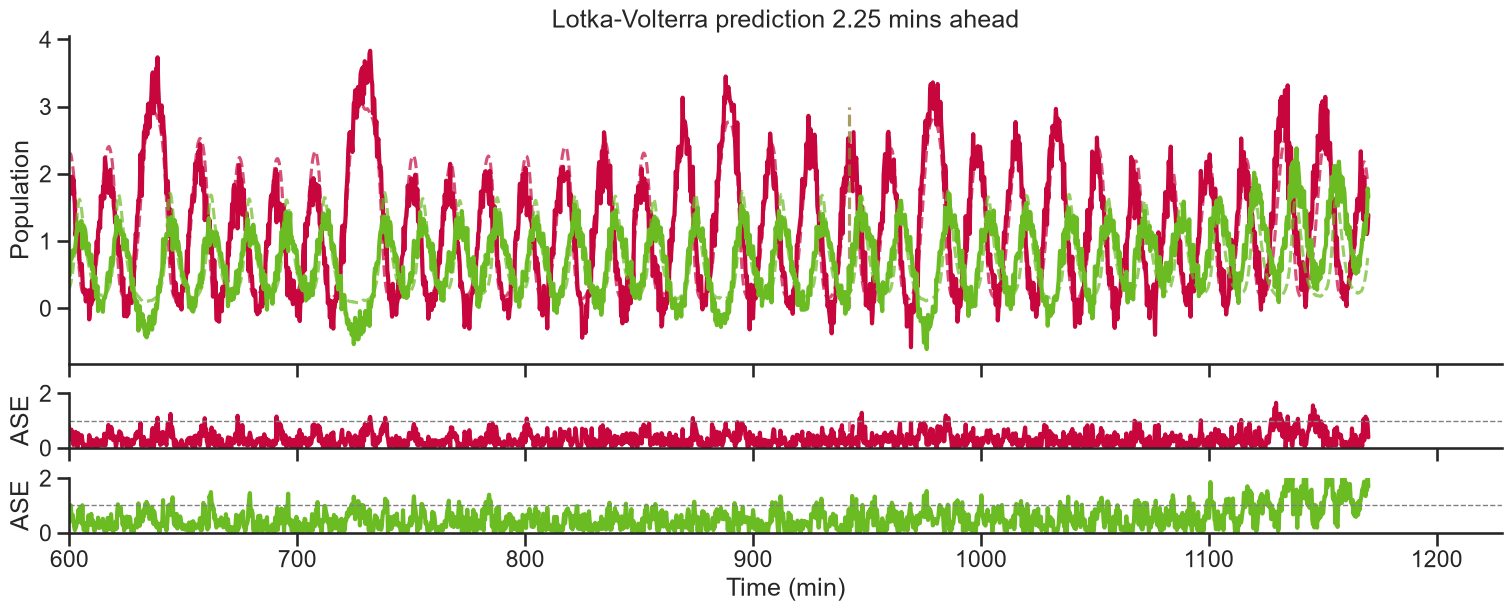

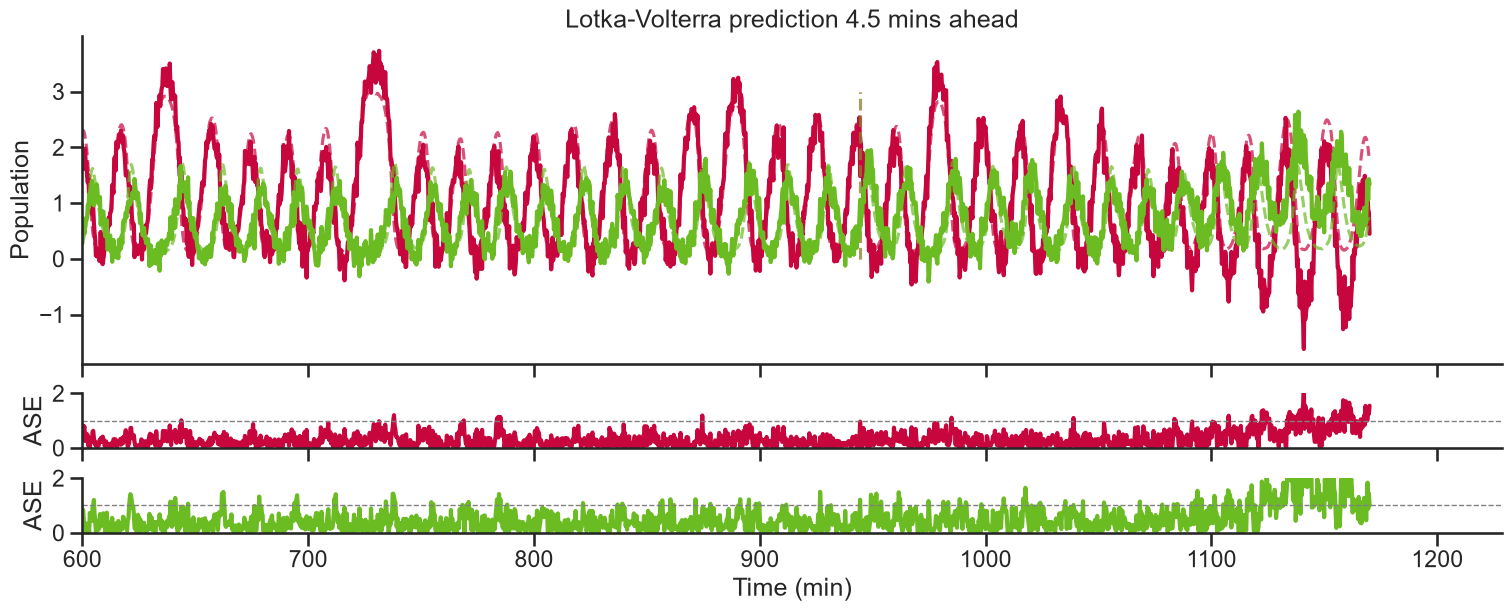

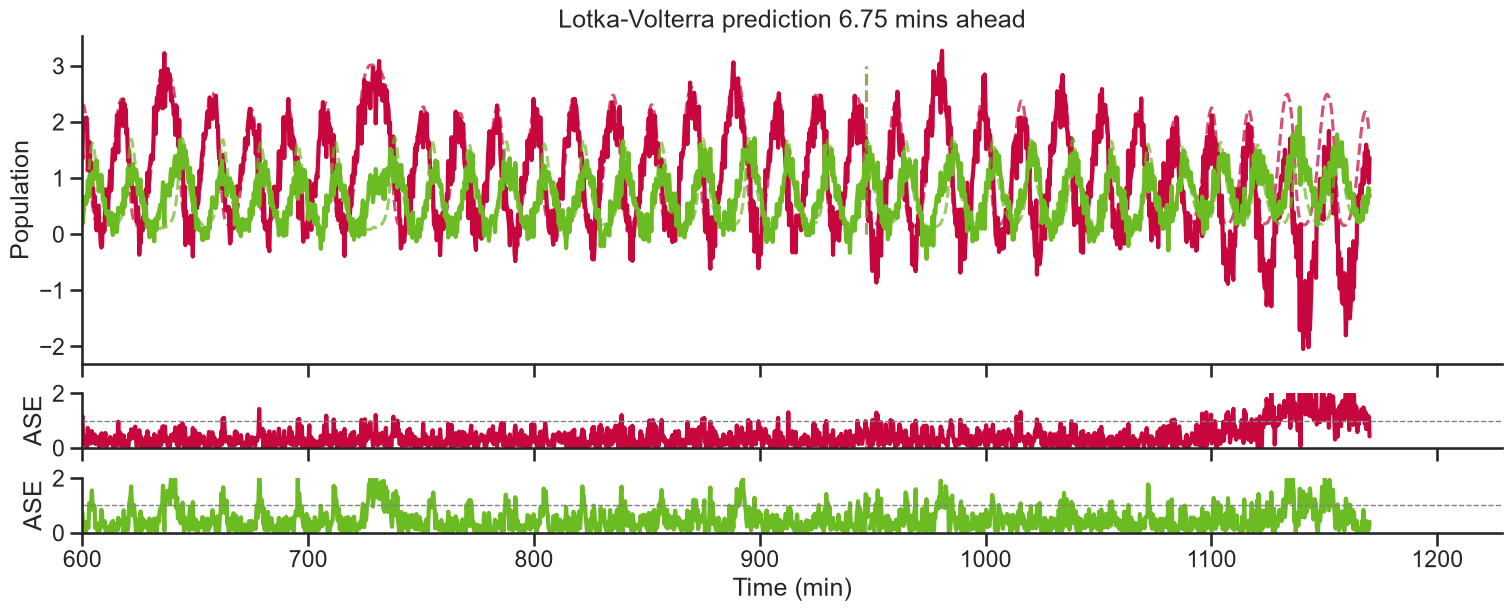

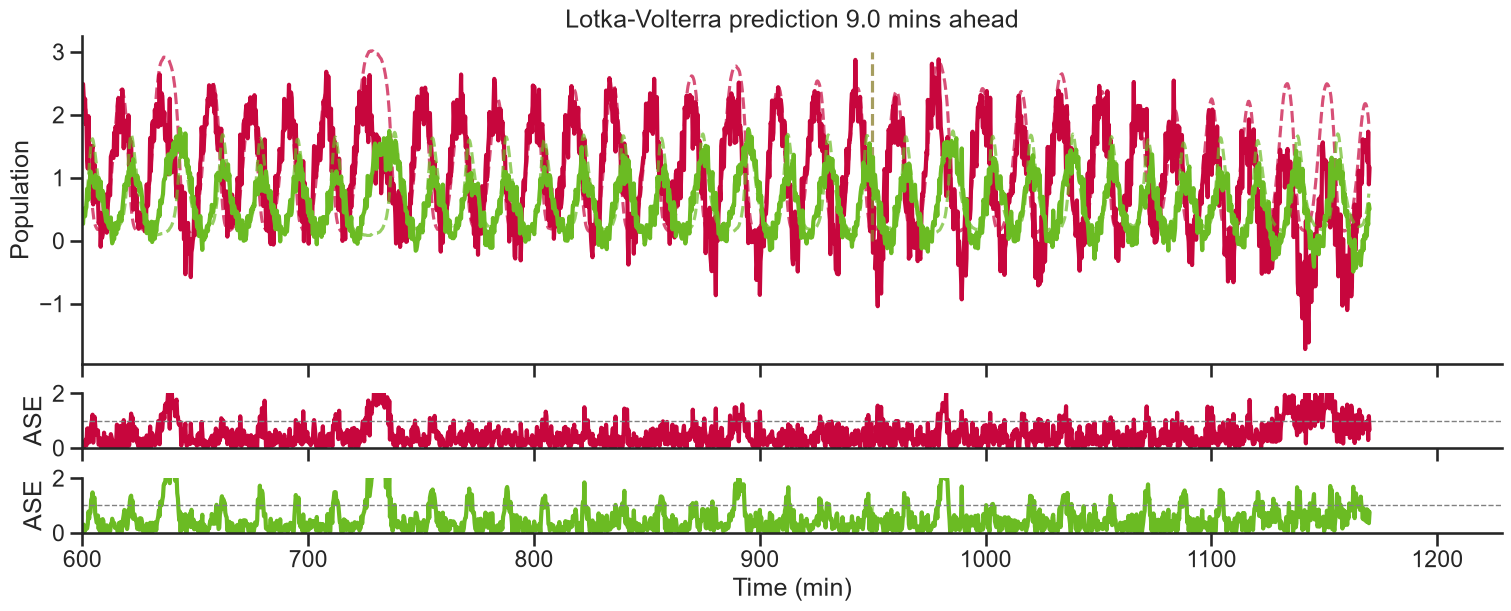

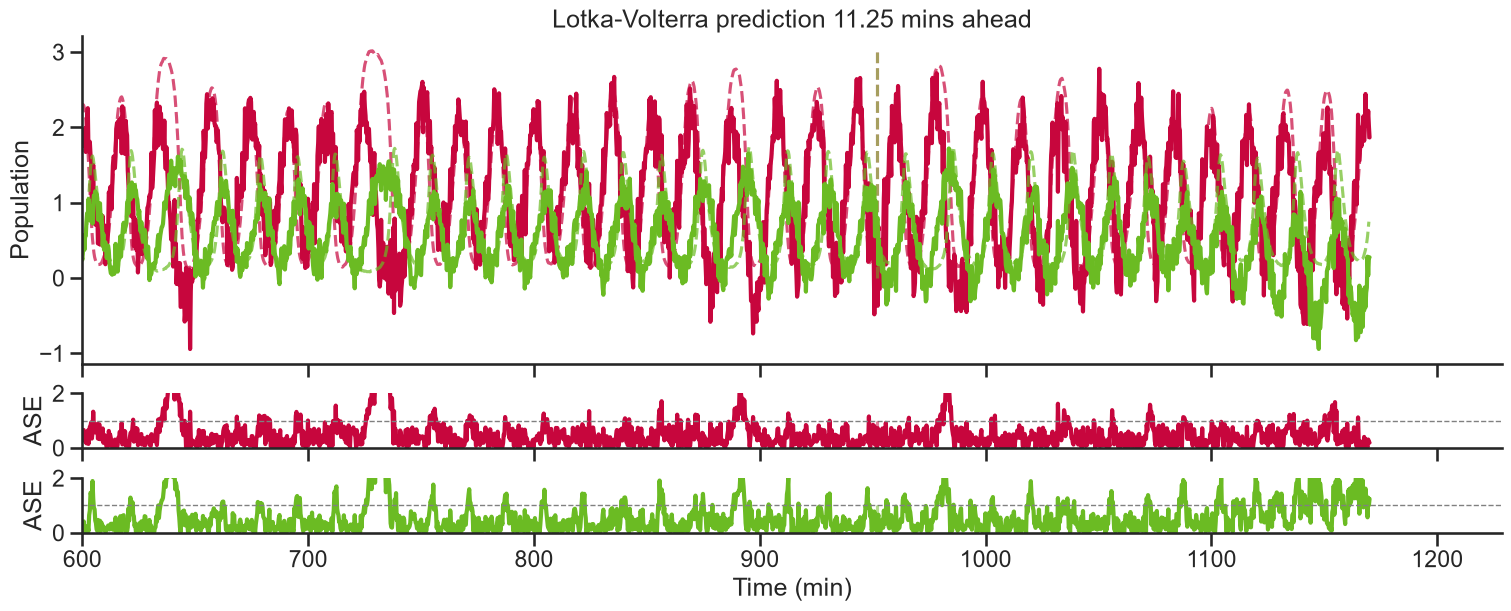

                 1         2         3         4         5
prey      0.351977  0.436228  0.601255  0.594484  0.436929
predator  0.686415  0.691489  0.523109  0.510207  0.650126


In [5]:
steps_ahead = [1,
               2,3,4,5
               ]

mase_score = pd.DataFrame()
step_pred_dict = {}

for step in steps_ahead:
    pred_steps, ase = task_prediction(preprocessed_data, task = task_df, input_names= input_names, colours= input_colours, steps_ahead= step)

    step_pred_dict[f'{step}'] = pred_steps

    mase_score[step] = ase


# if save:
#     mase_score.to_csv(save_path/f'high_res_MASE_scores.csv')

print (mase_score)

